In [1]:
import numpy as np
import pandas as pd
import itertools
import pubmed_parser as pp
from pathlib import Path
import matplotlib.pyplot as plt
from datetime import date
import re
from tqdm import tqdm
import time
from pybedtools import BedTool
import random
import math
import pickle
import time

today = date.today()

# Create Preset Ranges for Closest Genes

In [8]:
# hg19_genes_in_both = pd.read_pickle('../data/STRING-and-Alex-genes-hg19.pkl')
# hg38_genes_in_both = pd.read_pickle('../data/STRING-and-Alex-genes-hg38.pkl')

chromosomes = {
    'chr1': 249250621,
    'chr2': 243199373,
    'chr3': 198022430,
    'chr4': 191154276,
    'chr5': 180915260,
    'chr6': 171115067,
    'chr7': 159138663,
    'chr8': 146364022,
    'chr9': 141213431,
    'chr10': 135534747,
    'chr11': 135006516,
    'chr12': 133851895,
    'chr13': 115169878,
    'chr14': 107349540,
    'chr15': 102531392,
    'chr16': 90354753,
    'chr17': 81195210,
    'chr18': 78077248,
    'chr19': 59128983,
    'chr20': 63025520,
    'chr21': 48129895,
    'chr22': 51304566,
    'chrX': 155270560,
    'chrY': 59373566
}

def randomGenCoord():
    chrm = random.choice(list(chromosomes))
    coord = random.randint(0, chromosomes[chrm])
    return chrm + ' ' + str(coord)
# print(randomGenCoord())

def findNearestGene(coord, gene_ranges):    
    # Subset genes_df to just same chromosome
    coord = coord.split(' ')
    chrm = coord[0]
    coord = int(coord[1])
    
    chrm_range = gene_ranges[chrm]
    chrm_range_list = list(chrm_range)
    
    for i, interval in enumerate(chrm_range_list):
        if coord in range(interval[0], interval[1]):
            return chrm_range[interval]
        

def gemstone():
    hg19_gene_ranges_fn = open('../data/hg19_gene_ranges.pkl', "rb")
    hg19_gene_ranges = pickle.load(hg19_gene_ranges_fn)
    
    hg38_gene_ranges_fn = open('../data/hg38_gene_ranges.pkl', "rb")
    hg38_gene_ranges = pickle.load(hg38_gene_ranges_fn)
    
    coord = randomGenCoord()
    print(coord)
    
    hg19_gene = findNearestGene(coord, hg19_gene_ranges)
    hg38_gene = findNearestGene(coord, hg38_gene_ranges)

    
    if hg19_gene == hg38_gene:
        print('gene is in both assemblies', hg19_gene)
        get_prot_associations(hg19_gene)
    else:
        print('hg19 gene', hg19_gene)
        get_prot_associations(hg19_gene)
        print('hg38 gene', hg38_gene)
        get_prot_associations(hg38_gene)
    
    


def process_bedfile(assembly):
    ## READ IN BED FILE WITH COORDINATES
    
    if assembly == 'hg19':
        gene_df = pd.read_csv('../data/hg19.gencode.v19.annotation.hgnc.longest.gtf.bed14',
                      delimiter='\t', header = None, index_col=3)
    elif assembly == 'hg38':
        gene_df = pd.read_csv('../data/hg38.gencode.v38.annotation.gtf.genePred.hgnc.longest.noChrM.bed',
                      delimiter='\t', header = None, index_col=3)
    
    genes_in_both = pd.read_pickle('../data/STRING-and-Alex-genes-' + assembly + '.pkl')
    
    gene_df = gene_df.rename({3:'gene_names', 0:'chr', 1:'start', 2:'end', 5:'strand', 9:'descriptor'}, axis=1)
    gene_df.index = gene_df.index.rename('gene_names')
    
    # Remove duplicate genes
    gene_df_no_dupes = gene_df[~gene_df.index.duplicated(keep='first')]
    print(gene_df_no_dupes.shape, gene_df.shape)

    # Remove duplicate genes from 'genes_in_both'
    genes_in_both_df = gene_df_no_dupes.loc[genes_in_both.preferred_name.tolist()].reset_index()
    genes_in_both_dup_removed = genes_in_both_df.drop_duplicates(subset=['gene_names'])
    print(genes_in_both_df.shape, genes_in_both_dup_removed.shape)
    genes_in_both_dup_removed.set_index('gene_names', inplace=True)
    return genes_in_both_dup_removed

def get_overlapping_genes(gene_df, assembly):
    protein_info_df = pd.read_csv('../data/9606.protein.info.v11.5.txt', delimiter='\t', index_col=0)
    gene_names = gene_df.index.tolist()
    genes_in_both = protein_info_df[protein_info_df['preferred_name'].isin(gene_names)]
    genes_in_both.to_pickle('../data/STRING-and-Alex-genes-' + assembly + '.pkl')
    return genes_in_both


def get_associations(assembly):
    if assembly == 'hg19':
        protein_assoc_sub = pd.read_pickle('../data/hg19-protein-associations.pkl')
    elif assembly == 'hg38':
        protein_assoc_sub = pd.read_pickle('../data/hg38-protein-associations.pkl')
    return protein_assoc_sub

# Get top 50 protein associations. Will give both hg19 and hg38 coordinates based on if closest gene is in both assemblies.
def get_prot_associations(gene):
    hg19_gene_df = process_bedfile('hg19')
    hg38_gene_df = process_bedfile('hg38')
    
    start_time = time.time()
    
    if gene in hg19_gene_df.index:
        hg19_protein_assoc_sub = get_associations('hg19')
        print("--- protein associations are %s seconds ---" % (time.time() - start_time))
        currTime = time.time()
        # hg19
        print(gene + ' HG19')
        assembly = 'hg19'
        specific_gene_df = hg19_protein_assoc_sub[hg19_protein_assoc_sub['protein1_pref'] == gene].sort_values('combined_score', ascending=False)

        specific_gene_info = hg19_gene_df.loc[specific_gene_df['protein2_pref'].tolist()].reset_index()
        specific_gene_info = specific_gene_info.drop_duplicates('gene_names')

        gene_insert = hg19_gene_df.loc[gene]
        gene_insert['gene_names'] = gene

        specific_gene_info['combined_score'] = specific_gene_df['combined_score'].tolist()
        specific_gene_info = specific_gene_info.append(gene_insert)

        idx = [-1] + [i for i in range(len(specific_gene_info)-1)]
        specific_gene_info = specific_gene_info.reset_index().iloc[idx]

        specific_gene_info = specific_gene_info[['chr', 'start', 'end', 'gene_names', 'combined_score', 'descriptor']][:50]
        print("--- protein df is %s seconds ---" % (time.time() - currTime))
        currTime = time.time()

        specific_gene_bed = BedTool.from_dataframe(specific_gene_info)
        fn = '/home/stsai/public_html/hg19_' + gene + '_associated_proteins.bed'
        specific_gene_bed.saveas(fn)
        print("--- saving bed file is %s seconds ---" % (time.time() - currTime))
        print(generate_ROI_url(assembly + '_' + gene+'_associated_proteins.bed', assembly))
        
    if gene in hg38_gene_df.index:
        hg38_protein_assoc_sub = get_associations('hg38')    
        print('\n \n \n' + gene + ' HG38')

        # hg38
        assembly = 'hg38'
        specific_gene_df = hg38_protein_assoc_sub[hg38_protein_assoc_sub['protein1_pref'] == gene].sort_values('combined_score', ascending=False)

        specific_gene_info = hg38_gene_df.loc[specific_gene_df['protein2_pref'].tolist()].reset_index()
        specific_gene_info = specific_gene_info.drop_duplicates('gene_names')

        gene_insert = hg38_gene_df.loc[gene]
        gene_insert['gene_names'] = gene

        specific_gene_info['combined_score'] = specific_gene_df['combined_score'].tolist()
        specific_gene_info = specific_gene_info.append(gene_insert)

        idx = [-1] + [i for i in range(len(specific_gene_info)-1)]
        specific_gene_info = specific_gene_info.reset_index().iloc[idx]

        specific_gene_info = specific_gene_info[['chr', 'start', 'end', 'gene_names', 'combined_score', 'descriptor']][:50]

        specific_gene_bed = BedTool.from_dataframe(specific_gene_info)
        fn = '/home/stsai/public_html/hg38_' + gene + '_associated_proteins.bed'
        specific_gene_bed.saveas(fn)

        print(generate_ROI_url(assembly + '_' + gene+'_associated_proteins.bed', assembly))

    

def generate_ROI_url(fn, assembly):
    if assembly == 'hg19':
        return 'https://epilogos.altius.org:3001/?application=viewer&mode=single&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2F' + fn
    elif assembly == 'hg38':
        return 'https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2F' + fn

In [17]:
# hg19_genes_in_both = get_overlapping_genes(hg19_gene_df, 'hg19')

# hg38_genes_in_both = get_overlapping_genes(hg38_gene_df, 'hg38')


hg19_proc_gene_df = process_bedfile('hg19')
hg38_proc_gene_df = process_bedfile('hg38')

(51806, 13) (52739, 13)
(18094, 14) (18094, 14)
(40175, 13) (41315, 13)
(18025, 14) (18025, 14)


In [6]:
# protein_assoc_df = pd.read_csv('../data/9606.protein.links.full.v11.5.txt', delimiter=' ', index_col=0)
# hg19_genes_in_both = pd.read_pickle('../data/STRING-and-Alex-genes-hg19.pkl')
# gene_ids = hg19_genes_in_both.index

# protein_assoc_sub = protein_assoc_df[protein_assoc_df['protein2'].isin(gene_ids)]
# protein_assoc_sub = protein_assoc_sub[protein_assoc_sub.index.isin(gene_ids)]
# protein_assoc_sub['protein1_pref'] = protein_assoc_sub.index.map(hg19_genes_in_both['preferred_name'])
# protein_assoc_sub['protein2_pref'] = protein_assoc_sub['protein2'].map(hg19_genes_in_both['preferred_name'])

# protein_assoc_sub.to_pickle('../data/hg19-protein-associations.pkl')


# protein_assoc_df = pd.read_csv('../data/9606.protein.links.full.v11.5.txt', delimiter=' ', index_col=0)
# hg38_genes_in_both = pd.read_pickle('../data/STRING-and-Alex-genes-hg38.pkl')
# gene_ids = hg38_genes_in_both.index

# protein_assoc_sub = protein_assoc_df[protein_assoc_df['protein2'].isin(gene_ids)]
# protein_assoc_sub = protein_assoc_sub[protein_assoc_sub.index.isin(gene_ids)]
# protein_assoc_sub['protein1_pref'] = protein_assoc_sub.index.map(hg38_genes_in_both['preferred_name'])
# protein_assoc_sub['protein2_pref'] = protein_assoc_sub['protein2'].map(hg38_genes_in_both['preferred_name'])
# protein_assoc_sub.to_pickle('../data/hg38-protein-associations.pkl')

# CALCULATED GENE RANGES

In [35]:
# hg19_gene_ranges = {}

# for chrm in chromosomes.keys():
#     chrm_genes = hg19_proc_gene_df[hg19_proc_gene_df['chr'] == chrm].sort_values(by='start')
#     start = 0
#     chrm_dict = {}
#     for i in range(1, len(chrm_genes)):
#         gene1 = chrm_genes.iloc[i-1, :]
#         gene2 = chrm_genes.iloc[i, :]
        
#         diff = (gene2.start - gene1.end)//2
#         chrm_dict[(start, gene1.end+diff)] = gene1.gene_names
#         start = gene2.start - diff
    
#     chrm_dict[(start, chromosomes[chrm])] = gene2.gene_names
#     hg19_gene_ranges[chrm] = chrm_dict

    
# hg38_gene_ranges = {}

# for chrm in chromosomes.keys():
#     chrm_genes = hg38_proc_gene_df[hg38_proc_gene_df['chr'] == chrm].sort_values(by='start')
#     start = 0
#     chrm_dict = {}
#     for i in range(1, len(chrm_genes)):
#         gene1 = chrm_genes.iloc[i-1, :]
#         gene2 = chrm_genes.iloc[i, :]
        
#         diff = (gene2.start - gene1.end)//2
#         chrm_dict[(start, gene1.end+diff)] = gene1.gene_names
#         start = gene2.start - diff
    
#     chrm_dict[(start, chromosomes[chrm])] = gene2.gene_names
#     hg38_gene_ranges[chrm] = chrm_dict
    
# print(hg38_gene_ranges)

In [38]:
# # create a binary pickle file 
# f = open("../data/hg19_gene_ranges.pkl","wb")

# # write the python object (dict) to pickle file
# pickle.dump(hg19_gene_ranges,f)

# # close file
# f.close()

# # create a binary pickle file 
# f = open("../data/hg38_gene_ranges.pkl","wb")

# # write the python object (dict) to pickle file
# pickle.dump(hg38_gene_ranges,f)

# # close file
# f.close()

# file_to_read = open('../data/gene_ranges.pkl', "rb")

# gene_ranges = pickle.load(file_to_read)
# gene_ranges

In [43]:
coord = randomGenCoord()
print(findNearestGene(coord, hg19_gene_ranges))
print(findNearestGene(coord, hg38_gene_ranges))

chr6 12051626
HIVEP1
chr6 12051626
HIVEP1


# Find closest gene

In [9]:
gemstone()

chr19 13213567
hg19 gene LYL1
(51806, 13) (52739, 13)
(18094, 14) (18094, 14)
(40175, 13) (41315, 13)
(18025, 14) (18025, 14)
--- protein associations are 2.9194860458374023 seconds ---
LYL1 HG19


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


--- protein df is 1.3721351623535156 seconds ---
--- saving bed file is 0.006738901138305664 seconds ---
https://epilogos.altius.org:3001/?application=viewer&mode=single&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2Fhg19_LYL1_associated_proteins.bed

 
 
LYL1 HG38


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2Fhg38_LYL1_associated_proteins.bed
hg38 gene CACNA1A
(51806, 13) (52739, 13)
(18094, 14) (18094, 14)
(40175, 13) (41315, 13)
(18025, 14) (18025, 14)
--- protein associations are 2.7056381702423096 seconds ---
CACNA1A HG19


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


--- protein df is 1.355698585510254 seconds ---
--- saving bed file is 0.021944761276245117 seconds ---
https://epilogos.altius.org:3001/?application=viewer&mode=single&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2Fhg19_CACNA1A_associated_proteins.bed

 
 
CACNA1A HG38


/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2Fhg38_CACNA1A_associated_proteins.bed


**READ IN PROTEIN ASSOCIATIONS**

Downloaded from STRING https://string-db.org/cgi/download?sessionId=inputgtsessionId&species_text=Homo+sapiens

In [27]:
# protein_info_df = pd.read_csv('../data/Literature_Search/9606.protein.info.v11.5.txt', delimiter='\t', index_col=0)

# genes_in_both = protein_info_df[protein_info_df['preferred_name'].isin(gene_names)]

# gene_ids = genes_in_both.index
# print(genes_in_both)
# genes_in_both.to_pickle('../data/Literature_Search/STRING-and-Alex-genes.pkl')

# genes_in_both = pd.read_pickle('../data/STRING-and-Alex-genes.pkl')


# protein_assoc_df = pd.read_csv('../data/9606.protein.links.v11.5.txt', delimiter=' ', index_col=0)
# print(protein_assoc_df.shape)


# protein_assoc_sub = protein_assoc_df[protein_assoc_df['protein2'].isin(gene_ids)]
# protein_assoc_sub = protein_assoc_sub[protein_assoc_sub.index.isin(gene_ids)]

In [30]:
protein_assoc_sub = pd.read_pickle('../data/hg19-protein-associations.pkl')

## READ IN STRING ASSOCIATIONS

genes_in_both_no_dupes = genes_in_both.drop_duplicates(subset='preferred_name')
print(genes_in_both.shape, genes_in_both_no_dupes.shape)

protein_assoc_df = pd.read_csv('../data/9606.protein.links.detailed.v11.5.txt', delimiter=' ', index_col=0)
gene_ids = genes_in_both.index

protein_assoc_sub = protein_assoc_df[protein_assoc_df['protein2'].isin(gene_ids)]
protein_assoc_sub = protein_assoc_sub[protein_assoc_sub.index.isin(gene_ids)]
protein_assoc_sub['protein1_pref'] = protein_assoc_sub.index.map(genes_in_both['preferred_name'])
protein_assoc_sub['protein2_pref'] = protein_assoc_sub['protein2'].map(genes_in_both['preferred_name'])

print(genes_in_both.columns)
print(protein_assoc_sub.columns)

(18059, 3) (18059, 3)
Index(['preferred_name', 'protein_size', 'annotation'], dtype='object')
Index(['protein2', 'neighborhood', 'fusion', 'cooccurence', 'coexpression',
       'experimental', 'database', 'textmining', 'combined_score',
       'protein1_pref', 'protein2_pref'],
      dtype='object')


In [31]:
# SEARCH FOR SPECIFIC GENE
gene = 'GATA1'
specific_gene_df = protein_assoc_sub[protein_assoc_sub['protein1_pref'] == gene].sort_values('combined_score', ascending=False)

# USE RANDOM COORDINATE 
# gene = findNearestGene(randomGenCoord(), gene_ranges)
# print(gene)
# specific_gene_df = protein_assoc_sub[protein_assoc_sub['protein1_pref'] == gene].sort_values('combined_score', ascending=False)

In [23]:
# hg19_proc_gene_df

,chr,start,end,4,strand,6,7,8,descriptor,10,11,12,13
gene_names,,,,,,,,,,,,,
ARF5,chr7,127228398,127231759,6,+,ENST00000000233,658,protein-coding,ADP ribosylation factor 5,127228552,127231353,"221,81,110,72,126,493,","0,738,1140,1721,2618,2868,"
M6PR,chr12,9068355,9094058,17,+,ENST00000536844,6752,protein-coding,"mannose-6-phosphate receptor, cation dependent",9083081,9092055,"310,162,111,81,150,24,56,493,269,148,212,115,1...","0,1870,3996,5225,5841,6873,6973,14675,16803,18..."
FKBP4,chr12,2904118,2913124,46,+,ENST00000001008,3720,protein-coding,FKBP prolyl isomerase 4,2904305,2912424,"292,145,143,121,157,91,84,186,240,808,","0,2185,2776,3753,4135,4897,5086,5439,6164,8198,"
CYP26B1,chr2,72356366,72375167,26,-,ENST00000001146,20581,protein-coding,cytochrome P450 family 26 subfamily B member 1,72359355,72374963,"3382,285,156,276,225,408,","0,3785,5523,5906,14751,18393,"
NDUFAF7,chr2,37458805,37476303,5,+,ENST00000474154,28816,protein-coding,NADH:ubiquinone oxidoreductase complex assembl...,37476303,37476303,"98,161,81,111,1116,63,144,174,1026,","0,443,4433,6094,9915,12248,14389,15793,16472,"
...,...,...,...,...,...,...,...,...,...,...,...,...,...
CERS1,chr19,18988719,19007536,8,-,ENST00000542296,14253,protein-coding,ceramide synthase 1,18989734,19004339,"1129,148,162,181,160,167,","0,1330,2363,6176,15505,18650,"
ZNF518A,chr10,97889828,97965044,0,+,ENST00000563195,29009,protein-coding,zinc finger protein 518A,97965044,97965044,"47,85,93,1369,","0,2514,3484,73847,"
SPATA31A5,chr9,90529407,90538572,0,+,ENST00000437823,32005,protein-coding,SPATA31 subfamily A member 5,90538572,90538572,"218,94,61,3406,","0,4762,5423,5759,"


In [33]:
specific_gene_df.to_pickle('../data/'+gene+'_top-STRING-associations-s3-individual.pkl')
specific_gene_df

,protein2,neighborhood,fusion,cooccurence,coexpression,experimental,database,textmining,combined_score,protein1_pref,protein2_pref
protein1,,,,,,,,,,,
9606.ENSP00000365858,9606.ENSP00000326630,0,0,0,0,828,900,990,999,GATA1,ZFPM1
9606.ENSP00000365858,9606.ENSP00000257818,0,0,0,192,896,600,991,999,GATA1,LMO2
9606.ENSP00000365858,9606.ENSP00000294339,0,0,0,232,735,600,991,999,GATA1,TAL1
9606.ENSP00000365858,9606.ENSP00000392466,0,0,0,0,245,600,990,996,GATA1,LDB1
9606.ENSP00000365858,9606.ENSP00000305918,0,0,0,53,828,0,978,996,GATA1,BRD3
...,...,...,...,...,...,...,...,...,...,...,...
9606.ENSP00000365858,9606.ENSP00000278616,0,0,0,0,0,0,151,150,GATA1,ATM
9606.ENSP00000365858,9606.ENSP00000216117,0,0,0,0,0,0,150,150,GATA1,HMOX1
9606.ENSP00000365858,9606.ENSP00000351520,0,0,0,0,0,0,151,150,GATA1,ENTPD4


**Create BED file for ROIurl**

In [6]:
gene_df = pd.read_csv('../data/hg19.gencode.v19.annotation.hgnc.longest.gtf.bed14',
                      delimiter='\t', header = None, index_col=3)

gene_df = gene_df.rename({3:'gene_names', 0:'chr', 1:'start', 2:'end', 5:'strand', 9:'descriptor'}, axis=1)
gene_df.index = gene_df.index.rename('gene_names')

# Remove duplicate genes
gene_df_no_dupes = gene_df[~gene_df.index.duplicated(keep='first')]
print(gene_df_no_dupes.shape, gene_df.shape)

# Remove duplicate genes from 'genes_in_both'
genes_in_both_df = gene_df_no_dupes.loc[genes_in_both.preferred_name.tolist()].reset_index()
genes_in_both_dup_removed = genes_in_both_df.drop_duplicates(subset=['gene_names'])
print(genes_in_both_df.shape, genes_in_both_dup_removed.shape)

(51806, 13) (52739, 13)
(18059, 14) (18059, 14)


In [7]:
# print(specific_gene_df['combined_score'])

specific_gene_info = gene_df.loc[specific_gene_df['protein2_pref'].tolist()].reset_index()
specific_gene_info = specific_gene_info.drop_duplicates('gene_names')

# print(gene_df.loc[gene])
gene_insert = gene_df.loc[gene]
gene_insert['gene_names'] = gene
# print(gene_insert)

specific_gene_info['combined_score'] = specific_gene_df['combined_score'].tolist()
specific_gene_info = specific_gene_info.append(gene_insert)

idx = [-1] + [i for i in range(len(specific_gene_info)-1)]
specific_gene_info = specific_gene_info.reset_index().iloc[idx]

specific_gene_info = specific_gene_info[['chr', 'start', 'end', 'gene_names', 'combined_score', 'descriptor']][:20]

specific_gene_info

# specific_gene_info[[3, 'descriptor']][:20]

/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


,chr,start,end,gene_names,combined_score,descriptor
1746,chrX,48644961,48652715,GATA1,NaN,GATA binding protein 1
0,chr16,88519724,88603424,ZFPM1,999.0,"zinc finger protein, FOG family member 1"
1,chr11,33880121,33913836,LMO2,999.0,LIM domain only 2
2,chr1,47681961,47697387,TAL1,999.0,"TAL bHLH transcription factor 1, erythroid dif..."
3,chr10,103867339,103880210,LDB1,996.0,LIM domain binding 1
4,chr9,136895426,136933139,BRD3,996.0,bromodomain containing 3
5,chr11,47376410,47400127,SPI1,995.0,Spi-1 proto-oncogene
6,chr22,41487789,41576081,EP300,994.0,E1A binding protein p300
7,chr19,1609292,1652604,TCF3,990.0,transcription factor 3
8,chr4,16503163,16900432,LDB2,988.0,LIM domain binding 2


In [8]:
specific_gene_bed = BedTool.from_dataframe(specific_gene_info)
fn = '/home/stsai/public_html/' + gene + '_associated_proteins.bed'
specific_gene_bed.saveas(fn)


<BedTool(/home/stsai/public_html/GATA1_associated_proteins.bed)>

In [11]:
print(generate_ROI_url(gene+'_associated_proteins.bed'))

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2FGATA1_associated_proteins.bed
https://epilogos.altius.org:3001/?application=viewer&mode=single&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2FGATA1_associated_proteins.bed


# Plotting Combined Score

In [56]:
specific_gene_plot = specific_gene_df.iloc[:50, :]
# specific_gene_plot

AttributeError: 'DataFrame' object has no attribute 'experimental'

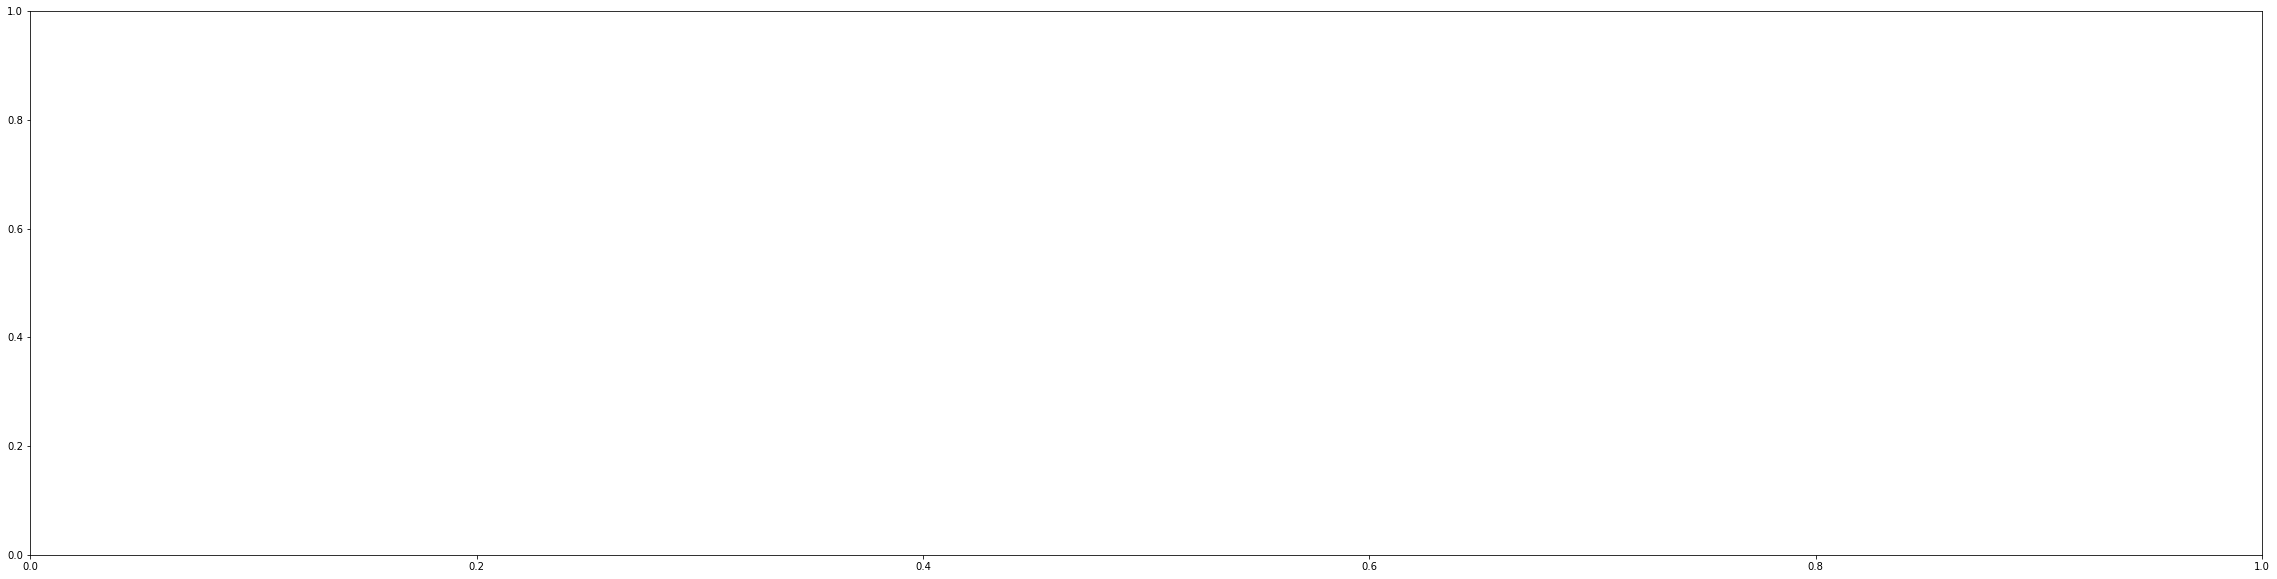

In [57]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = specific_gene_plot.protein2_pref

ax.bar(labels, specific_gene_plot.experimental, width, label='Experimental')
ax.bar(labels, specific_gene_plot.database, width, bottom=specific_gene_plot.experimental,
       label='Database')
ax.bar(labels, specific_gene_plot.coexpression, width, bottom=specific_gene_plot.experimental+specific_gene_plot.database,
       label='Coexpression')
ax.bar(labels, specific_gene_plot.textmining, width, bottom=specific_gene_plot.experimental+specific_gene_plot.database + specific_gene_plot.coexpression,
       label='Textmining')
ax.bar(labels, specific_gene_plot.fusion, width, bottom=specific_gene_plot.experimental+specific_gene_plot.database + specific_gene_plot.coexpression + specific_gene_plot.textmining,
       label='Fusion')
ax.bar(labels, specific_gene_plot.neighborhood, width, bottom=specific_gene_plot.experimental+specific_gene_plot.database + specific_gene_plot.coexpression + specific_gene_plot.textmining + specific_gene_plot.fusion,
       label='Neighborhood')

ax.set_ylabel('Scores')
ax.set_title(gene + ' Scores by Channel')
ax.legend()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_' + gene + '-top50-sum-barplot.png')

In [124]:
labels

protein1
9606.ENSP00000367747    PIP5KL1
9606.ENSP00000367747    PIP5K1B
9606.ENSP00000367747    PIP5K1C
9606.ENSP00000367747    PIP5K1A
9606.ENSP00000367747    PIP4K2A
9606.ENSP00000367747    PIP4K2C
9606.ENSP00000367747     INPP5E
9606.ENSP00000367747     INPP5B
9606.ENSP00000367747      SYNJ2
9606.ENSP00000367747      SYNJ1
9606.ENSP00000367747     INPP5A
9606.ENSP00000367747       OCRL
9606.ENSP00000367747       IPMK
9606.ENSP00000367747      ITPKA
9606.ENSP00000367747     INPP5J
9606.ENSP00000367747     INPP5K
9606.ENSP00000367747     PIK3CD
9606.ENSP00000367747      ITPKB
9606.ENSP00000367747     PIK3CA
9606.ENSP00000367747     PIK3CB
9606.ENSP00000367747     PIK3CG
9606.ENSP00000367747      ITPKC
9606.ENSP00000367747      PLCG1
9606.ENSP00000367747      PLCG2
9606.ENSP00000367747       PTEN
9606.ENSP00000367747     MINPP1
9606.ENSP00000367747      PLCD1
9606.ENSP00000367747      PLCE1
9606.ENSP00000367747      PLCH1
9606.ENSP00000367747      PLCD3
9606.ENSP00000367747     PLA2R1

In [125]:
global prior 
prior = 0.041

def compute_prior_away(score):
    score = score/1000

    if score < prior: score = prior
    score_no_prior = (score - prior) / (1 - prior)

    return score_no_prior

In [126]:
neighborhood_prior_removed = specific_gene_df.textmining.apply(compute_prior_away)

In [127]:
neighborhood_prior_removed

protein1
9606.ENSP00000367747    0.411887
9606.ENSP00000367747    0.344108
9606.ENSP00000367747    0.201251
9606.ENSP00000367747    0.225235
9606.ENSP00000367747    0.101147
                          ...   
9606.ENSP00000367747    0.000000
9606.ENSP00000367747    0.057351
9606.ENSP00000367747    0.045881
9606.ENSP00000367747    0.000000
9606.ENSP00000367747    0.006257
Name: textmining, Length: 873, dtype: float64

In [128]:
channels = ['neighborhood', 'fusion', 'cooccurence', 'coexpression', 'experimental', 'database', 'textmining']

# 1-combined_score = channel_prod

# channel_score / channel_prod = fraction


temp_combined_score = 1-((specific_gene_plot['combined_score'].divide(1000)*(1-prior)))
# print(temp_combined_score)


processed_neighborhood = 1-(specific_gene_plot['neighborhood'].apply(compute_prior_away))
# print(processed_neighborhood)

processed_fusion = 1-(specific_gene_plot['fusion'].apply(compute_prior_away))
# print(processed_fusion)

processed_cooccurence = 1-(specific_gene_plot['cooccurence'].apply(compute_prior_away))
# print(processed_cooccurence)

processed_coexpression = 1-(specific_gene_plot['coexpression'].apply(compute_prior_away))
# print(processed_coexpression)

processed_experimental = 1-(specific_gene_plot['experimental'].apply(compute_prior_away))
# print(processed_experimental)

processed_database = 1-(specific_gene_plot['database'].apply(compute_prior_away))
# print(processed_database)

processed_textmining = 1-(specific_gene_plot['textmining'].apply(compute_prior_away))
# print(processed_textmining)



neighborhood_fraction = processed_neighborhood / temp_combined_score 
fusion_fraction = processed_fusion / temp_combined_score 
cooccurence_fraction = processed_cooccurence / temp_combined_score 
coexpression_fraction = processed_coexpression / temp_combined_score 
experimental_fraction = processed_experimental / temp_combined_score 
database_fraction = processed_database / temp_combined_score
textmining_fraction = processed_textmining / temp_combined_score 


# print(temp_combined_score)
# print(processed_textmining)

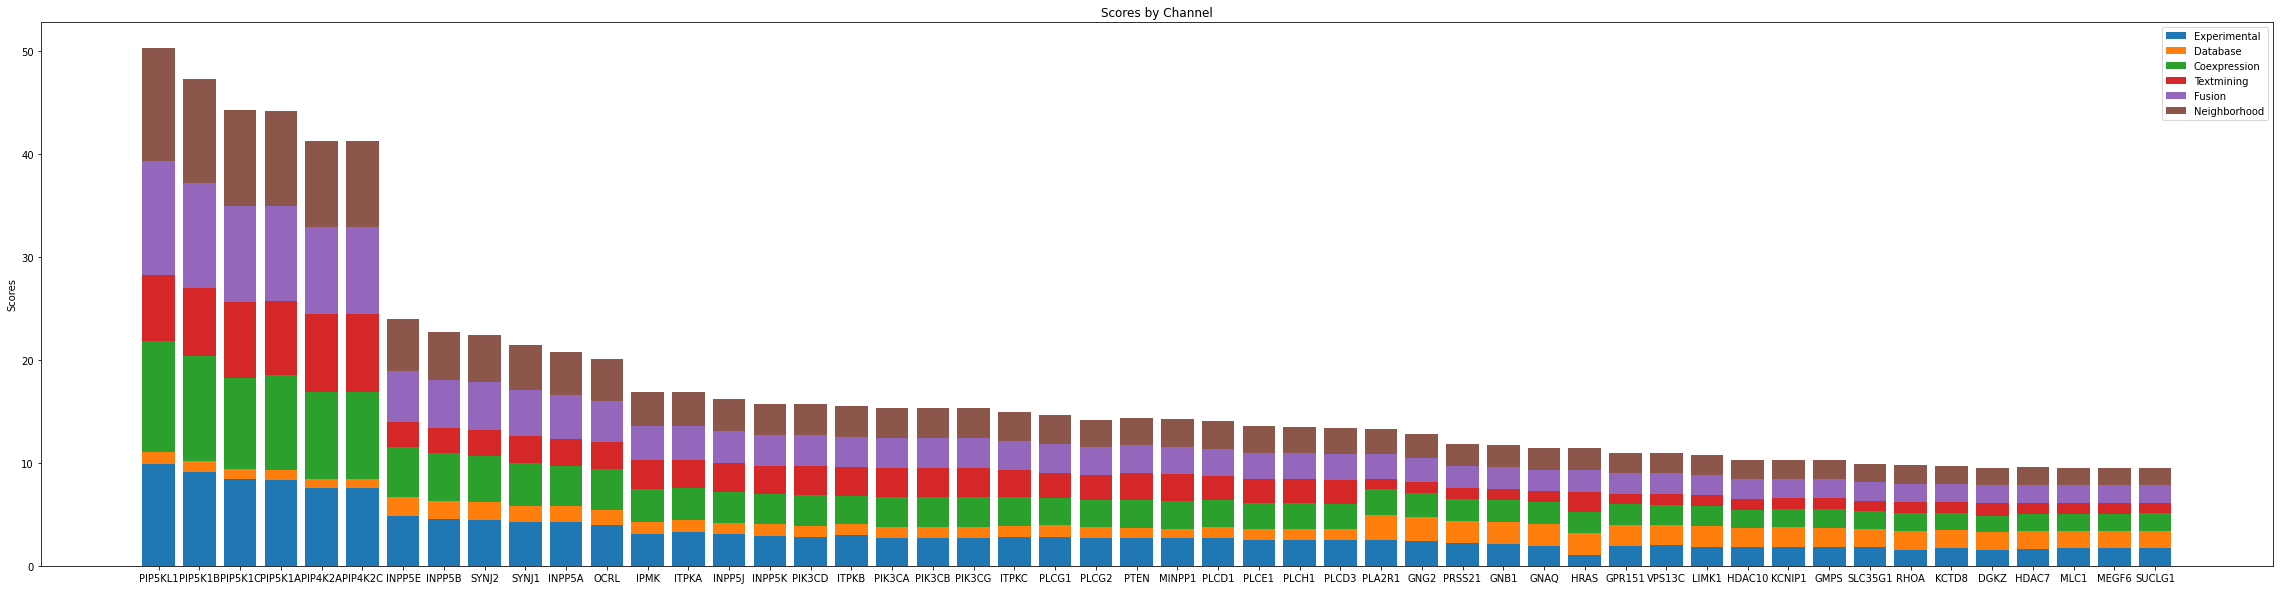

In [130]:
width = 0.8       # the width of the bars: can also be len(x) sequence

fig, ax = plt.subplots(figsize=(40, 10))
labels = specific_gene_plot.protein2_pref

ax.bar(labels, experimental_fraction, width, label='Experimental')
ax.bar(labels, database_fraction, width, bottom=experimental_fraction,
       label='Database')
ax.bar(labels, coexpression_fraction, width, bottom=experimental_fraction+database_fraction,
       label='Coexpression')
ax.bar(labels, textmining_fraction, width, bottom=experimental_fraction+database_fraction + coexpression_fraction,
       label='Textmining')
ax.bar(labels, fusion_fraction, width, bottom=experimental_fraction+database_fraction + coexpression_fraction + textmining_fraction,
       label='Fusion')
ax.bar(labels, neighborhood_fraction, width, bottom=experimental_fraction+database_fraction + coexpression_fraction + textmining_fraction + fusion_fraction,
       label='Neighborhood')

ax.set_ylabel('Scores')
ax.set_title('Scores by Channel')
ax.legend()

plt.savefig('../output/plots/ST_' + today.strftime("%Y-%m-%d") + '_' + gene + '-top50-product-barplot.png')

In [ ]:
total = processed_neighborhood + processed_fusion + processed_cooccurence + processed_coexpression + processed_experimental = 1-(specific_gene_plot['experimental'].apply(compute_prior_away))
+ processed_database

# Test pipeline functions

In [24]:
gene = 'GATA1'
get_prot_associations(gene)

(51806, 13) (52739, 13)
(18094, 14) (18094, 14)
(40175, 13) (41315, 13)
(18025, 14) (18025, 14)
HG19 



/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/series.py:1056: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  cacher_needs_updating = self._check_is_chained_assignment_possible()
/home/stsai/.conda/envs/RecommenderSystems/lib/python3.8/site-packages/pandas/core/indexing.py:1724: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_with_indexer_missing(indexer, value)


https://epilogos.altius.org:3001/?application=viewer&mode=single&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2Fhg19_GATA1_associated_proteins.bed

 
 
HG38 

https://index.altius.org:3000/?application=viewer&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~stsai%2Fhg38_GATA1_associated_proteins.bed
